In [288]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

### Read data from file

In [289]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (70692, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [290]:
df.columns = df.columns.str.lower()
df.columns

Index(['diabetes_binary', 'highbp', 'highchol', 'cholcheck', 'bmi', 'smoker',
       'stroke', 'heartdiseaseorattack', 'physactivity', 'fruits', 'veggies',
       'hvyalcoholconsump', 'anyhealthcare', 'nodocbccost', 'genhlth',
       'menthlth', 'physhlth', 'diffwalk', 'sex', 'age', 'education',
       'income'],
      dtype='str')

In [291]:
# yake backup
df_copy=df.copy()
df=df_copy.copy()
df.head()

,diabetes_binary,highbp,highchol,cholcheck,bmi,smoker,stroke,heartdiseaseorattack,physactivity,fruits,...,anyhealthcare,nodocbccost,genhlth,menthlth,physhlth,diffwalk,sex,age,education,income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


## Exploratory Data Analysis (EDA)

The objective of this section is to understand the dataset,
identify missing values, analyze feature distributions,
and explore relationships between input features and
the target variable (diabetes_binary).

In [292]:
# 1. Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. Dataset information
df.info()

# 3. Statistical summary
display(df.describe().T.round(2))

# 4. Missing values
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(df) * 100).round(2)
})

display(missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
))

# 5. Duplicate records
print("Duplicate records:", df.duplicated().sum())

Number of rows: 70692
Number of columns: 22
<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   diabetes_binary       70692 non-null  float64
 1   highbp                70692 non-null  float64
 2   highchol              70692 non-null  float64
 3   cholcheck             70692 non-null  float64
 4   bmi                   70692 non-null  float64
 5   smoker                70692 non-null  float64
 6   stroke                70692 non-null  float64
 7   heartdiseaseorattack  70692 non-null  float64
 8   physactivity          70692 non-null  float64
 9   fruits                70692 non-null  float64
 10  veggies               70692 non-null  float64
 11  hvyalcoholconsump     70692 non-null  float64
 12  anyhealthcare         70692 non-null  float64
 13  nodocbccost           70692 non-null  float64
 14  genhlth               70692 non-null 

,count,mean,std,min,25%,50%,75%,max
diabetes_binary,70692.0,0.50,0.50,0.0,0.0,0.5,1.0,1.0
highbp,70692.0,0.56,0.50,0.0,0.0,1.0,1.0,1.0
highchol,70692.0,0.53,0.50,0.0,0.0,1.0,1.0,1.0
cholcheck,70692.0,0.98,0.16,0.0,1.0,1.0,1.0,1.0
bmi,70692.0,29.86,7.11,12.0,25.0,29.0,33.0,98.0
smoker,70692.0,0.48,0.50,0.0,0.0,0.0,1.0,1.0
stroke,70692.0,0.06,0.24,0.0,0.0,0.0,0.0,1.0
heartdiseaseorattack,70692.0,0.15,0.35,0.0,0.0,0.0,0.0,1.0
physactivity,70692.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0
fruits,70692.0,0.61,0.49,0.0,0.0,1.0,1.0,1.0


,Missing Values,Missing Percentage
diabetes_binary,0,0.0
highbp,0,0.0
highchol,0,0.0
cholcheck,0,0.0
bmi,0,0.0
smoker,0,0.0
stroke,0,0.0
heartdiseaseorattack,0,0.0
physactivity,0,0.0
fruits,0,0.0


Duplicate records: 1635


### Target Variable Distribution

diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64

Target Distribution (%):
diabetes_binary
0.0    50.0
1.0    50.0
Name: proportion, dtype: float64


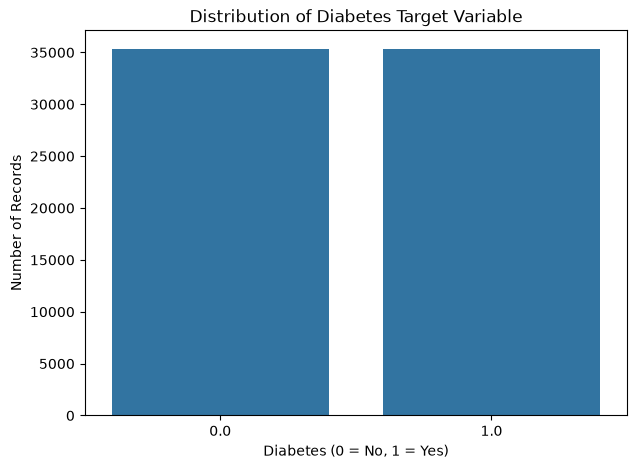

In [293]:
# Target variable distribution
target_counts = df['diabetes_binary'].value_counts().sort_index()

print(target_counts)

# Target distribution percentage
target_percentage = (
    df['diabetes_binary']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nTarget Distribution (%):")
print(target_percentage.round(2))

# Visualization
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='diabetes_binary'
)

plt.title('Distribution of Diabetes Target Variable')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')

plt.show()

### Numerical Feature Distribution

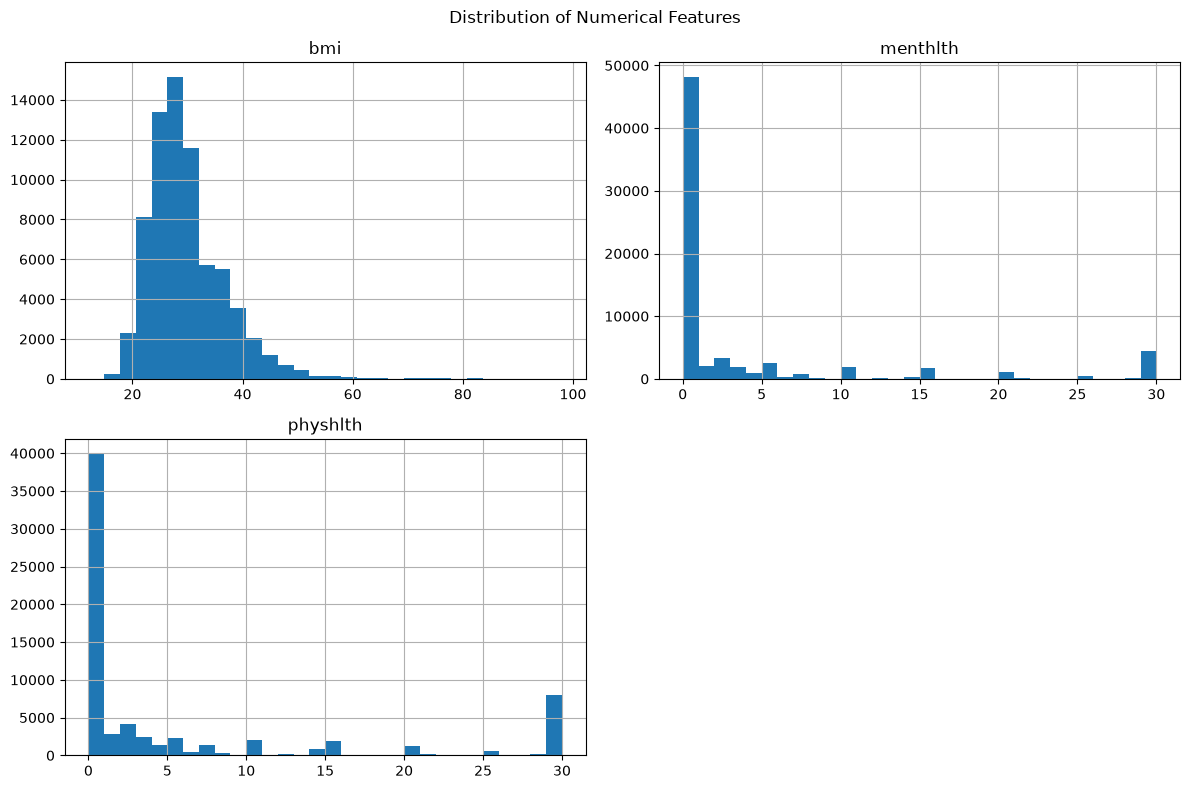

In [294]:
numerical_features = [
    'bmi',
    'menthlth',
    'physhlth'
]

df[numerical_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

### Categorical and Binary Feature Analysis

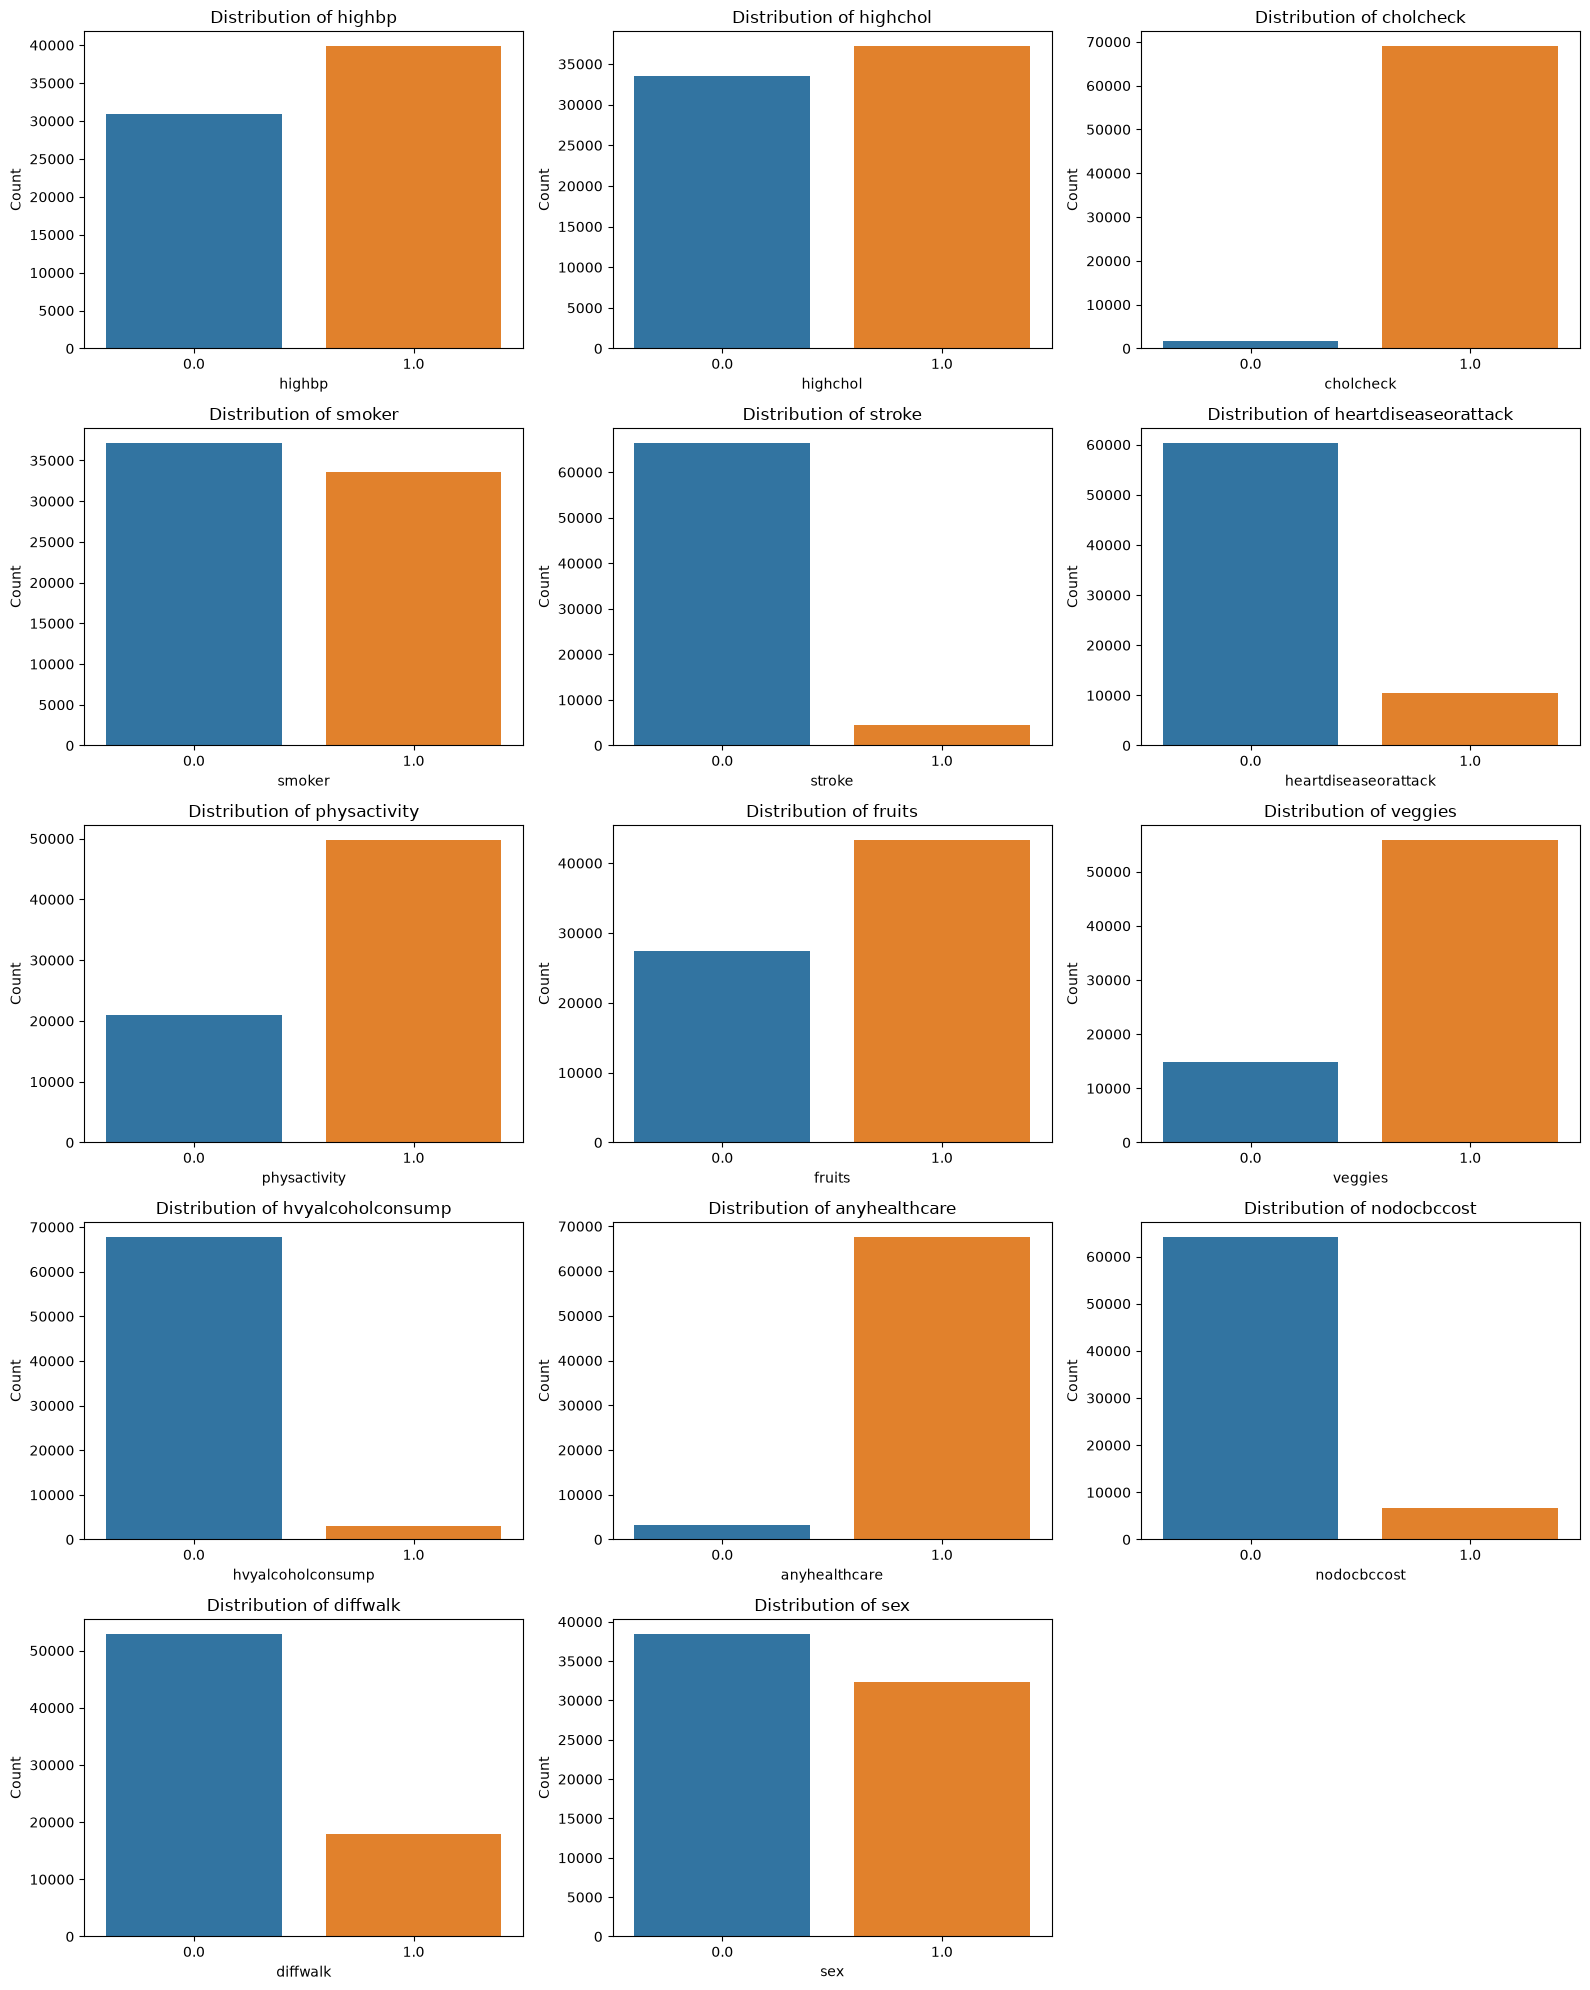

In [295]:
binary_features = [
    'highbp',
    'highchol',
    'cholcheck',
    'smoker',
    'stroke',
    'heartdiseaseorattack',
    'physactivity',
    'fruits',
    'veggies',
    'hvyalcoholconsump',
    'anyhealthcare',
    'nodocbccost',
    'diffwalk',
    'sex'
]

fig, axes = plt.subplots(5, 3, figsize=(16, 20))

for feature, ax in zip(binary_features, axes.flatten()):
    sns.countplot(
        data=df,
        x=feature,
        hue=feature,
        legend=False,
        ax=ax
    )

    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Count')

for ax in axes.flatten()[len(binary_features):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Correlation Analysis

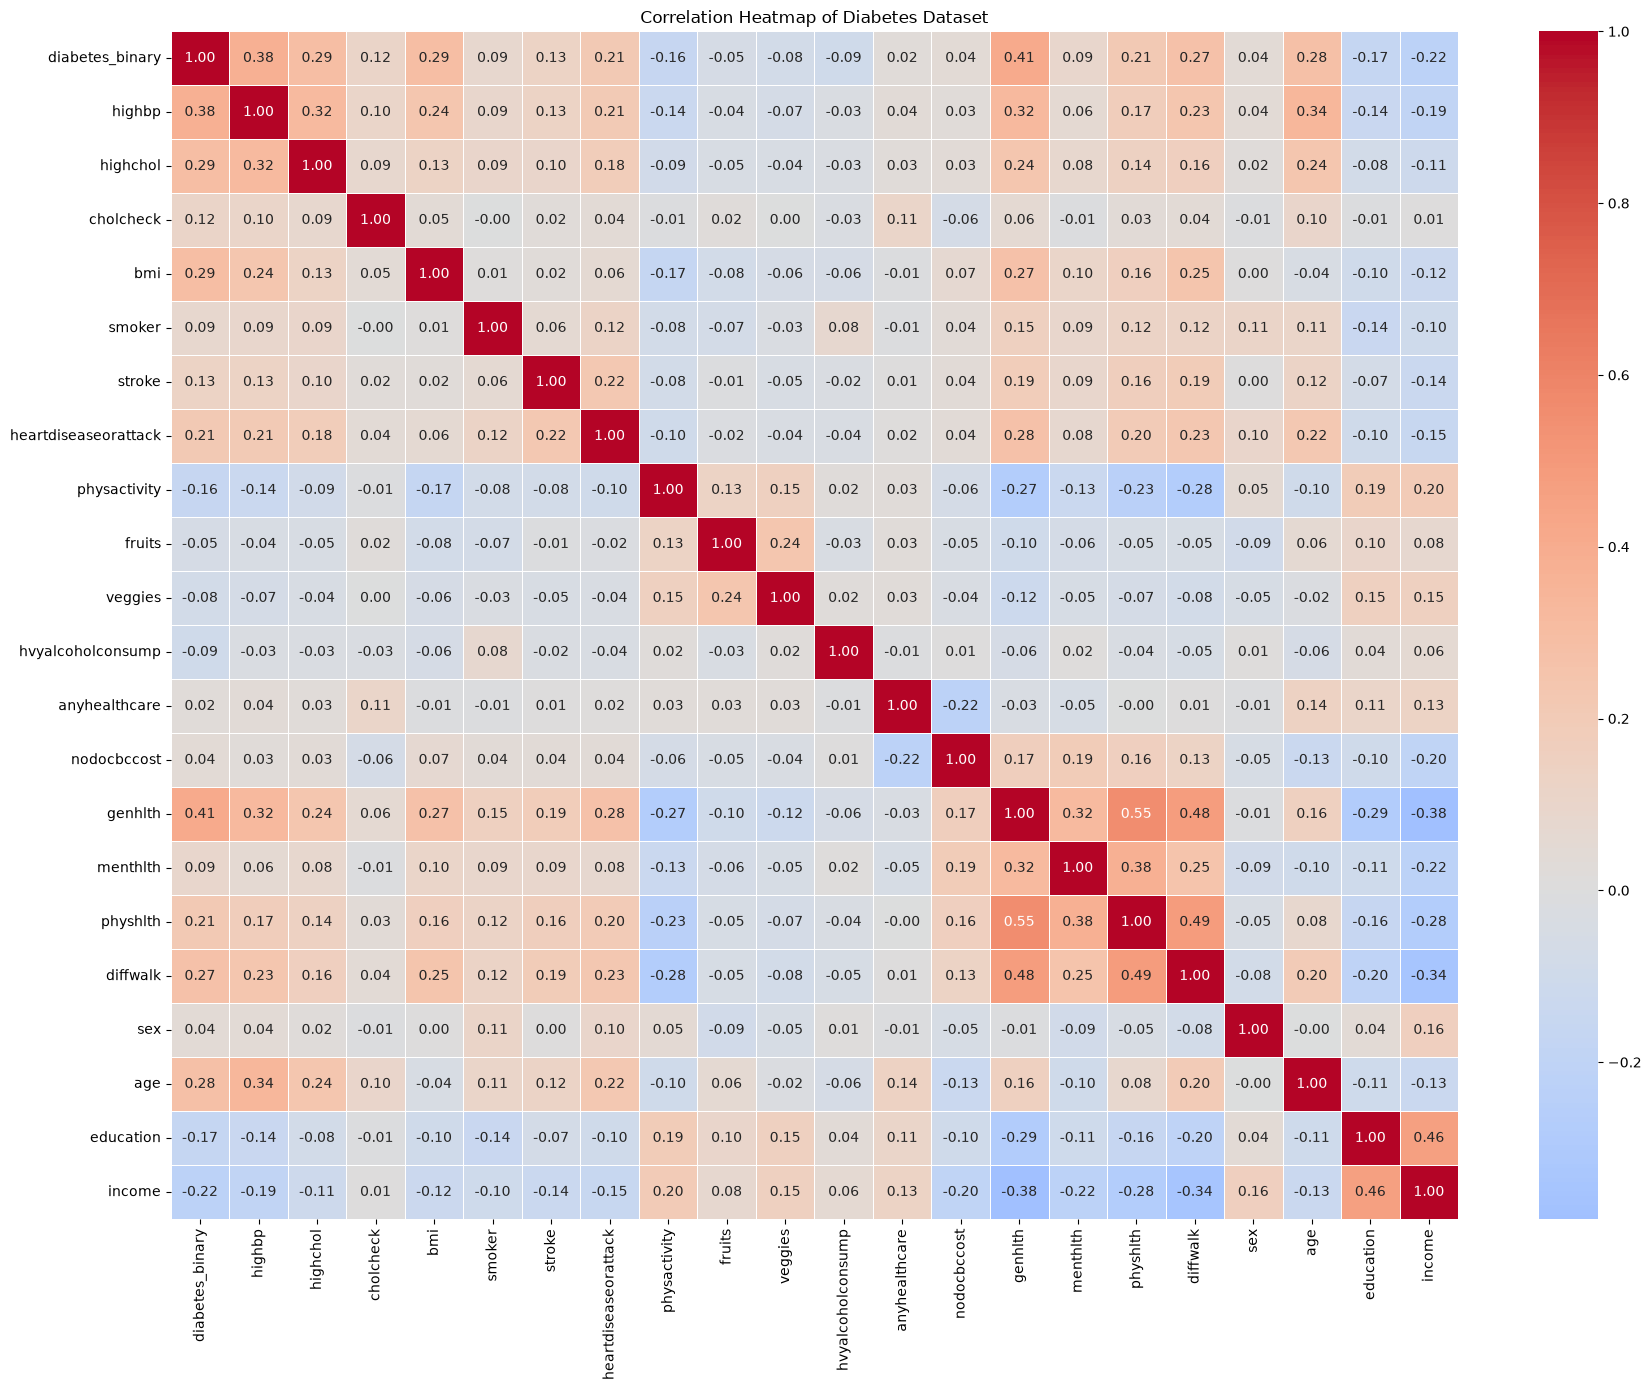

In [296]:
plt.figure(figsize=(18, 14))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Diabetes Dataset')
plt.tight_layout()
plt.show()

In [297]:
target_correlation = (
    correlation_matrix['diabetes_binary']
    .drop('diabetes_binary')
    .sort_values(key=abs, ascending=False)
)

display(target_correlation.to_frame(name='Correlation with Diabetes'))

,Correlation with Diabetes
genhlth,0.407612
highbp,0.381516
bmi,0.293373
highchol,0.289213
age,0.278738
diffwalk,0.272646
income,-0.224449
physhlth,0.213081
heartdiseaseorattack,0.211523
education,-0.170481


### Feature Importance Using Mutual Information

Mutual Information measures the dependency between each input
feature and the target variable. Higher values indicate that
the feature provides more information about the target.

In [301]:
df.head()

,diabetes_binary,highbp,highchol,cholcheck,bmi,smoker,stroke,heartdiseaseorattack,physactivity,fruits,...,anyhealthcare,nodocbccost,genhlth,menthlth,physhlth,diffwalk,sex,age,education,income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [303]:
from sklearn.metrics import mutual_info_score

def mutual_info_churn_score(series):
    return mutual_info_score(df['diabetes_binary'], series)

# apply to all catogorical variables
score = df.apply(mutual_info_churn_score)
score.sort_values(ascending=False)

diabetes_binary         0.693147
genhlth                 0.092682
highbp                  0.074794
bmi                     0.057299
age                     0.046827
highchol                0.042432
diffwalk                0.038327
income                  0.027702
physhlth                0.026642
heartdiseaseorattack    0.023294
education               0.015269
physactivity            0.012684
stroke                  0.008190
cholcheck               0.007394
menthlth                0.004679
hvyalcoholconsump       0.004656
smoker                  0.003703
veggies                 0.003154
fruits                  0.001463
sex                     0.000987
nodocbccost             0.000842
anyhealthcare           0.000269
dtype: float64

### EDA Summary and Key Findings

The dataset contains 70,692 records and 22 columns, including 21 independent features and one target variable (`diabetes_binary`).

Key observations from the exploratory data analysis:

1. The dataset contains no missing values.
2. The target variable is perfectly balanced, with 35,346 records in each class (50% diabetic and 50% non-diabetic).
3. BMI distribution is right-skewed, with most observations concentrated between approximately 20 and 35.
4. The correlation analysis identified `genhlth`, `highbp`, `bmi`, `highchol`, and `age` as some of the features most positively associated with diabetes.
5. Mutual Information analysis identified `genhlth`, `highbp`, `bmi`, `age`, and `highchol` as the five most informative features.
6. Features such as `anyhealthcare`, `nodocbccost`, and `sex` showed relatively low Mutual Information scores.

These findings provide an initial understanding of the dataset and help guide subsequent model training and evaluation.


In [305]:
selected_features = [
    'genhlth',
    'highbp',
    'age',
    'highchol',
    'diffwalk',
    'income',
    'heartdiseaseorattack',
    'education',
    'physactivity',
    'physhlth',
    'bmi'
]

target = 'diabetes_binary'

X = df[selected_features]
y = df[target]

print("Selected features:", len(selected_features))
print("X shape:", X.shape)
print("y shape:", y.shape)

Selected features: 11
X shape: (70692, 11)
y shape: (70692,)


In [306]:
df_selected = df[selected_features]
df_selected

,genhlth,highbp,age,highchol,diffwalk,income,heartdiseaseorattack,education,physactivity,physhlth,bmi
0,3.0,1.0,4.0,0.0,0.0,8.0,0.0,6.0,1.0,30.0,26.0
1,3.0,1.0,12.0,1.0,0.0,8.0,0.0,6.0,0.0,0.0,26.0
2,1.0,0.0,13.0,0.0,0.0,8.0,0.0,6.0,1.0,10.0,26.0
3,3.0,1.0,11.0,1.0,0.0,8.0,0.0,6.0,1.0,3.0,28.0
4,2.0,0.0,8.0,0.0,0.0,8.0,0.0,5.0,1.0,0.0,29.0
...,...,...,...,...,...,...,...,...,...,...,...
70687,4.0,0.0,6.0,1.0,0.0,1.0,0.0,4.0,0.0,0.0,37.0
70688,2.0,0.0,10.0,1.0,1.0,6.0,1.0,3.0,0.0,0.0,29.0
70689,5.0,1.0,13.0,1.0,1.0,4.0,1.0,6.0,0.0,0.0,25.0
70690,4.0,1.0,11.0,1.0,1.0,4.0,0.0,2.0,0.0,0.0,18.0


In [307]:
#backup of data
df_eda = df_selected.copy()

In [320]:
df = df_eda.copy()
# Add target variable as it will be required during train test split
df['diabetes_binary'] = y
df

,genhlth,highbp,age,highchol,diffwalk,income,heartdiseaseorattack,education,physactivity,physhlth,bmi,diabetes_binary
0,3.0,1.0,4.0,0.0,0.0,8.0,0.0,6.0,1.0,30.0,26.0,0.0
1,3.0,1.0,12.0,1.0,0.0,8.0,0.0,6.0,0.0,0.0,26.0,0.0
2,1.0,0.0,13.0,0.0,0.0,8.0,0.0,6.0,1.0,10.0,26.0,0.0
3,3.0,1.0,11.0,1.0,0.0,8.0,0.0,6.0,1.0,3.0,28.0,0.0
4,2.0,0.0,8.0,0.0,0.0,8.0,0.0,5.0,1.0,0.0,29.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
70687,4.0,0.0,6.0,1.0,0.0,1.0,0.0,4.0,0.0,0.0,37.0,1.0
70688,2.0,0.0,10.0,1.0,1.0,6.0,1.0,3.0,0.0,0.0,29.0,1.0
70689,5.0,1.0,13.0,1.0,1.0,4.0,1.0,6.0,0.0,0.0,25.0,1.0
70690,4.0,1.0,11.0,1.0,1.0,4.0,0.0,2.0,0.0,0.0,18.0,1.0


### Map column values for selected 09 categorical features

In [321]:
highbp_values = {
    0: 'no high bp',
    1: 'high bp'
}

df.highbp = df.highbp.map(highbp_values)

highchol_values = {
    0: 'no high col',
    1: 'high col'
}

df.highchol = df.highchol.map(highchol_values)


heartdiseaseorattack_values = {
    0: 'no',
    1: 'yes'
}

df.heartdiseaseorattack = df.heartdiseaseorattack.map(heartdiseaseorattack_values)

physactivity_values = {
    0: 'no',
    1: 'yes'
}

df.physactivity = df.physactivity.map(physactivity_values)


genhlth_values = {
    1: 'excellent',
    2: 'very good',
    3: 'good',
    4: 'fair',
    5: 'poor'
}

df.genhlth = df.genhlth.map(genhlth_values)

diffwalk_values = {
    0: 'no',
    1: 'yes'

}

df.diffwalk = df.diffwalk.map(diffwalk_values)


# Code Value	Meaning (Age Group Range)
# 1	18 to 24 years old
# 2	25 to 29 years old
# 3	30 to 34 years old
# 4	35 to 39 years old
# 5	40 to 44 years old
# 6	45 to 49 years old
# 7	50 to 54 years old
# 8	55 to 59 years old
# 9	60 to 64 years old
# 10	65 to 69 years old
# 11	70 to 74 years old
# 12	75 to 79 years old
# 13	80 years old or older


age_values = {
    1.0: "24",
    2.0: "29",
    3.0: "34",
    4.0: "39",
    5.0: "44",
    6.0: "49",
    7.0: "54",
    8.0: "59",
    9.0: "64",
    10.0: "69",
    11.0: "74",
    12.0: "79",
    13.0: "80"
}

df.age = df.age.map(age_values)

#     1.0: "Never attended / Kindergarten only",
#     2.0: "Elementary (Grades 1-8)",
#     3.0: "Some High School (Grades 9-11)",
#     4.0: "High School Graduate / GED",
#     5.0: "Some College / Technical School",
#     6.0: "College Graduate (4+ years)"

education_values = {
    1: "Never attended Kindergarten only",
    2: "Elementary (Grades 1-8)",
    3: "Some High School (Grades 9-11)",
    4: "High School Graduate / GED",
    5: "Some College / Technical School",
    6: "College Graduate (4+ years)"
}

df.education = df.education.map(education_values)


# Code Value	Meaning (Annual Household Income Range)
# 1	Less than $10,000
# 2	$10,000 to less than $15,000
# 3	$15,000 to less than $20,000
# 4	$20,000 to less than $25,000
# 5	$25,000 to less than $35,000
# 6	$35,000 to less than $50,000
# 7	$50,000 to less than $75,000
# 8	$75,000 or more

income_values = {
    1: "Less than 10,000",
    2: "10,000 to 15,000",
    3: "15,000 to 20,000",
    4: "20,000 to 25,000",
    5: "25,000 to 35,000",
    6: "35,000 to 50,000",
    7: "50,000 to 75,000",
    8: "75,000 or more"
}

df.income = df.income.map(income_values)

In [322]:
df.head()

,genhlth,highbp,age,highchol,diffwalk,income,heartdiseaseorattack,education,physactivity,physhlth,bmi,diabetes_binary
0,good,high bp,39,no high col,no,"75,000 or more",no,College Graduate (4+ years),yes,30.0,26.0,0.0
1,good,high bp,79,high col,no,"75,000 or more",no,College Graduate (4+ years),no,0.0,26.0,0.0
2,excellent,no high bp,80,no high col,no,"75,000 or more",no,College Graduate (4+ years),yes,10.0,26.0,0.0
3,good,high bp,74,high col,no,"75,000 or more",no,College Graduate (4+ years),yes,3.0,28.0,0.0
4,very good,no high bp,59,no high col,no,"75,000 or more",no,Some College / Technical School,yes,0.0,29.0,0.0


In [323]:
categorical = df.dtypes[df.dtypes == 'str'].index
for c in categorical:
    df[c]=df[c].str.lower().str.replace(' ','_')
categorical

Index(['genhlth', 'highbp', 'age', 'highchol', 'diffwalk', 'income',
       'heartdiseaseorattack', 'education', 'physactivity'],
      dtype='str')

In [324]:
df.head(5)

,genhlth,highbp,age,highchol,diffwalk,income,heartdiseaseorattack,education,physactivity,physhlth,bmi,diabetes_binary
0,good,high_bp,39,no_high_col,no,"75,000_or_more",no,college_graduate_(4+_years),yes,30.0,26.0,0.0
1,good,high_bp,79,high_col,no,"75,000_or_more",no,college_graduate_(4+_years),no,0.0,26.0,0.0
2,excellent,no_high_bp,80,no_high_col,no,"75,000_or_more",no,college_graduate_(4+_years),yes,10.0,26.0,0.0
3,good,high_bp,74,high_col,no,"75,000_or_more",no,college_graduate_(4+_years),yes,3.0,28.0,0.0
4,very_good,no_high_bp,59,no_high_col,no,"75,000_or_more",no,some_college_/_technical_school,yes,0.0,29.0,0.0


In [440]:
# Check missing values after categorical mapping

print("Missing values after mapping:")
display(df.isnull().sum())

# Check unique values in categorical features

categorical_features = [
    'genhlth',
    'highbp',
    'age',
    'highchol',
    'diffwalk',
    'income',
    'heartdiseaseorattack',
    'education',
    'physactivity'
]

for col in categorical_features:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Missing values after mapping:


genhlth                 0
highbp                  0
age                     0
highchol                0
diffwalk                0
income                  0
heartdiseaseorattack    0
education               0
physactivity            0
physhlth                0
bmi                     0
diabetes_binary         0
dtype: int64


genhlth:
genhlth
good         23427
very_good    19872
fair         13303
excellent     8282
poor          5808
Name: count, dtype: int64

highbp:
highbp
high_bp       39832
no_high_bp    30860
Name: count, dtype: int64

age:
age
69    10856
64    10112
59     8603
74     8044
54     6872
80     5426
79     5394
49     4648
44     3520
39     2793
34     2049
29     1396
24      979
Name: count, dtype: int64

highchol:
highchol
high_col       37163
no_high_col    33529
Name: count, dtype: int64

diffwalk:
diffwalk
no     52826
yes    17866
Name: count, dtype: int64

income:
income
75,000_or_more      20646
50,000_to_75,000    11425
35,000_to_50,000    10287
25,000_to_35,000     8010
20,000_to_25,000     6658
15,000_to_20,000     5557
10,000_to_15,000     4498
less_than_10,000     3611
Name: count, dtype: int64

heartdiseaseorattack:
heartdiseaseorattack
no     60243
yes    10449
Name: count, dtype: int64

education:
education
college_graduate_(4+_years)         26020
some_college_/_te

In [325]:
df_clean = df.copy()

In [439]:
df = df_clean.copy()

### Train test split of data in three (train, validation and test)

In [441]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df,test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train,test_size=0.25, random_state=11)

In [442]:
df_train = df_train.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

In [443]:
df_train

,genhlth,highbp,age,highchol,diffwalk,income,heartdiseaseorattack,education,physactivity,physhlth,bmi,diabetes_binary
0,very_good,high_bp,64,high_col,no,"75,000_or_more",no,college_graduate_(4+_years),yes,0.0,28.0,1.0
1,good,high_bp,39,no_high_col,no,"less_than_10,000",no,some_college_/_technical_school,no,30.0,30.0,1.0
2,good,high_bp,54,high_col,no,"50,000_to_75,000",no,college_graduate_(4+_years),yes,1.0,24.0,0.0
3,excellent,no_high_bp,64,no_high_col,no,"50,000_to_75,000",no,high_school_graduate_/_ged,yes,0.0,23.0,0.0
4,very_good,no_high_bp,24,no_high_col,no,"75,000_or_more",no,some_college_/_technical_school,yes,0.0,25.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
42409,very_good,high_bp,69,high_col,no,"20,000_to_25,000",no,high_school_graduate_/_ged,yes,2.0,42.0,1.0
42410,very_good,no_high_bp,24,no_high_col,no,"15,000_to_20,000",no,high_school_graduate_/_ged,yes,0.0,23.0,0.0
42411,excellent,high_bp,79,high_col,no,"less_than_10,000",no,elementary_(grades_1-8),yes,0.0,32.0,0.0
42412,poor,high_bp,59,high_col,yes,"50,000_to_75,000",no,some_college_/_technical_school,no,30.0,30.0,1.0


In [444]:
#here status = default means True. we need to encode it
y_train = (df_train.diabetes_binary == 1).astype('int').values
y_val = (df_val.diabetes_binary == 1).astype('int').values
y_test = (df_test.diabetes_binary == 1).astype('int').values
y_full_train = (df_full_train.diabetes_binary == 1).astype('int').values

In [445]:
# Remove target variable from df
del df_train['diabetes_binary']
del df_val['diabetes_binary']
del df_test['diabetes_binary']
del df_full_train['diabetes_binary']

## Train and validate using 'Clasification' model

In [446]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
import xgboost as xgb

from sklearn.metrics import roc_auc_score

In [447]:
train_dicts = df_train.to_dict(orient='records')

In [448]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [450]:
logistic_model = LogisticRegression()

In [451]:
logistic_model.fit(X_train, y_train)

c:\Users\7N\PycharmProjects\Midterm Project_Diabetes_prediction\diabetes project midterm\diabetes_env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [454]:
feature_names = dv.get_feature_names_out()
feature_names

array(['age=24', 'age=29', 'age=34', 'age=39', 'age=44', 'age=49',
       'age=54', 'age=59', 'age=64', 'age=69', 'age=74', 'age=79',
       'age=80', 'bmi', 'diffwalk=no', 'diffwalk=yes',
       'education=college_graduate_(4+_years)',
       'education=elementary_(grades_1-8)',
       'education=high_school_graduate_/_ged',
       'education=never_attended_kindergarten_only',
       'education=some_college_/_technical_school',
       'education=some_high_school_(grades_9-11)', 'genhlth=excellent',
       'genhlth=fair', 'genhlth=good', 'genhlth=poor',
       'genhlth=very_good', 'heartdiseaseorattack=no',
       'heartdiseaseorattack=yes', 'highbp=high_bp', 'highbp=no_high_bp',
       'highchol=high_col', 'highchol=no_high_col',
       'income=10,000_to_15,000', 'income=15,000_to_20,000',
       'income=20,000_to_25,000', 'income=25,000_to_35,000',
       'income=35,000_to_50,000', 'income=50,000_to_75,000',
       'income=75,000_or_more', 'income=less_than_10,000',
       'physactiv

In [456]:
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("All feature names:", len(feature_names))
print("Feature names unique:", len(set(feature_names)))

Training shape: (42414, 44)
Validation shape: (14139, 44)
All feature names: 44
Feature names unique: 44


In [457]:
y_pred = logistic_model.predict_proba(X_val)[:, 1]
classification_score = roc_auc_score(y_val, y_pred)
classification_score

0.8256374329922258

In [459]:
#store above score to refer later
model_score = {}

In [460]:
# model_score['Classifiction'] = classification_score.round(4)
model_score['Classifiction'] = round(classification_score, 4)

In [461]:
model_score

{'Classifiction': 0.8256}

## Train and validate using 'Decision Tree' model

In [342]:
dt = DecisionTreeClassifier()

dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [343]:
y_pred = dt.predict_proba(X_val)[:,1]
decisiontree_score = roc_auc_score(y_val, y_pred)
decisiontree_score

0.654893420847539

In [344]:
model_score['Decision_Tree'] = round(decisiontree_score, 4)

### Tune decision tree

In [345]:
# from above iteration, we got max_depth for d=4, 5, 6. Now lets check another parameter mini_sample_leaf for these 3 top values
scores = []

for d in [1,2,3,4,5,6,7, 8, 9, 10,15, 20, None]:
    for s in [1,2,5,10,15,20,100, 200, 500]:
            dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
            dt.fit(X_train, y_train)

            y_pred = dt.predict_proba(X_val)[:,1]
            auc = roc_auc_score(y_val, y_pred)
            scores.append((d,s,auc))
        

In [346]:
# convert above scores to df
cols = ['max_depth', 'mini_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=cols)
df_scores

,max_depth,mini_samples_leaf,auc
0,1.0,1,0.690257
1,1.0,2,0.690257
2,1.0,5,0.690257
3,1.0,10,0.690257
4,1.0,15,0.690257
...,...,...,...
112,NaN,15,0.791107
113,NaN,20,0.796619
114,NaN,100,0.810075
115,NaN,200,0.808388


In [347]:
df_scores_pivot = df_scores.pivot(index='mini_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                                                  \
max_depth            NaN  1.0    2.0    3.0    4.0    5.0    6.0    7.0    
mini_samples_leaf                                                          
1                  0.656  0.69  0.735  0.768  0.788  0.797  0.805  0.807   
2                  0.694  0.69  0.735  0.768  0.788  0.797  0.805  0.807   
5                  0.754  0.69  0.735  0.768  0.788  0.797  0.805  0.807   
10                 0.779  0.69  0.735  0.768  0.788  0.798  0.804  0.807   
15                 0.791  0.69  0.735  0.768  0.788  0.798  0.805  0.808   
20                 0.797  0.69  0.735  0.768  0.788  0.798  0.804  0.807   
100                0.810  0.69  0.735  0.767  0.788  0.797  0.804  0.807   
200                0.808  0.69  0.735  0.767  0.788  0.797  0.804  0.806   
500                0.805  0.69  0.735  0.767  0.788  0.797  0.803  0.804   

                                                      
max_depth           8.0    9.0    10.0   15.0   20.0  
mini_samples_leaf                                     
1                  0.807  0.802  0.796  0.737  0.683  
2                  0.807  0.803  0.798  0.747  0.711  
5                  0.808  0.805  0.803  0.777  0.761  
10                 0.808  0.808  0.806  0.791  0.782  
15                 0.810  0.809  0.808  0.798  0.792  
20                 0.809  0.809  0.808  0.801  0.797  
100                0.808  0.809  0.810  0.810  0.810  
200                0.808  0.808  0.808  0.808  0.808  
500                0.805  0.805  0.805  0.805  0.805

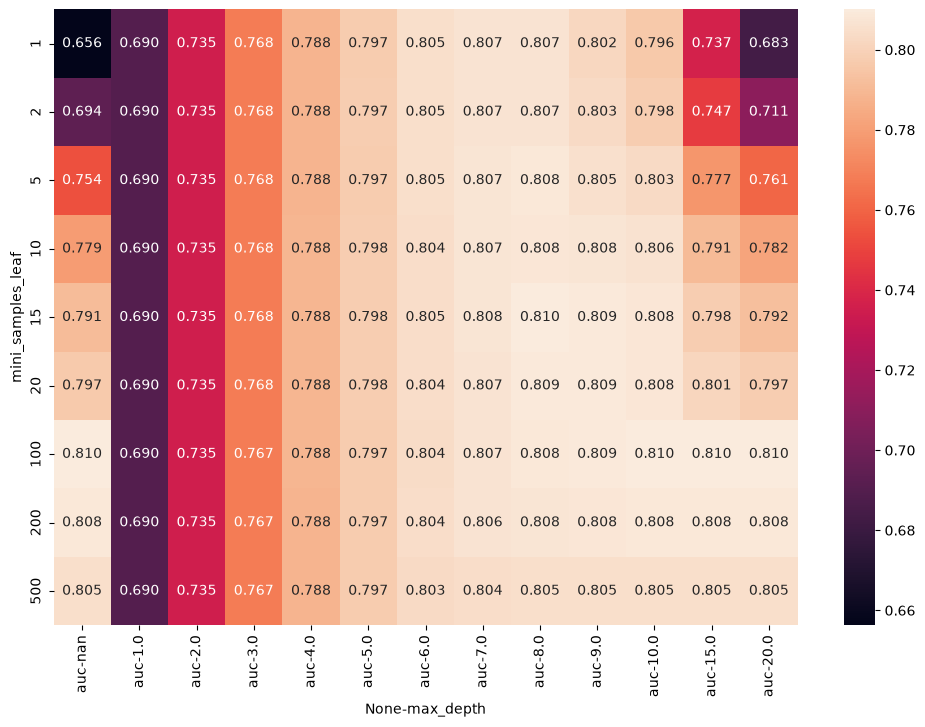

In [348]:
#now visulize using heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df_scores_pivot, annot=True, fmt='0.3f')
plt.show()

In [349]:
#Lets train and check our model
dt = DecisionTreeClassifier(max_depth=15, min_samples_leaf=100)
dt.fit(X_train, y_train)

y_pred = dt.predict_proba(X_val)[:,1]
auc = roc_auc_score(y_val, y_pred)
auc

0.810081864986601

### save this score

In [350]:
model_score['Tuned_Decision_Tree'] = round(auc, 4)
model_score

{'Classifiction': 0.8256,
 'Decision_Tree': 0.6549,
 'Tuned_Decision_Tree': 0.8101}

## Train on Random forest

In [351]:
from sklearn.ensemble import RandomForestClassifier

In [352]:
rf = RandomForestClassifier(n_estimators=10, random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [353]:
y_pred = rf.predict_proba(X_val)[:,1]
auc_rf = roc_auc_score(y_val, y_pred)
auc_rf

0.7667021560340961

In [354]:
#save this score
model_score['Random_forest'] = round(auc_rf, 4)
model_score

{'Classifiction': 0.8256,
 'Decision_Tree': 0.6549,
 'Tuned_Decision_Tree': 0.8101,
 'Random_forest': 0.7667}

## Lets tune random forest

In [355]:
# Now lets tune trees in RF for diff params
scores = []

for d in [5,10,15]:
    for n in range (10,201,10):
            rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1,n_jobs=-1)
            rf.fit(X_train, y_train)

            y_pred = rf.predict_proba(X_val)[:,1]
            auc = roc_auc_score(y_val, y_pred)
            scores.append((d,n,auc))

In [356]:
cols=['max_depth', 'no_estimators', 'auc']
df_scores= pd.DataFrame(scores, columns=cols)
df_scores.head()

,max_depth,no_estimators,auc
0,5,10,0.807186
1,5,20,0.808700
2,5,30,0.809655
3,5,40,0.809705
4,5,50,0.809520


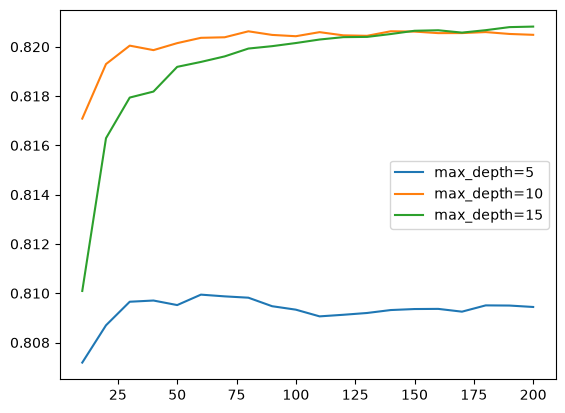

In [357]:
for d in [5,10,15]:
    df_subset = df_scores[df_scores.max_depth==d]
    plt.plot(df_subset.no_estimators, df_subset.auc, label='max_depth=%d' % d)
    
plt.legend()

In [358]:
# Best max_depth
max_depth = 10

In [359]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1,
                                    n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

In [360]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

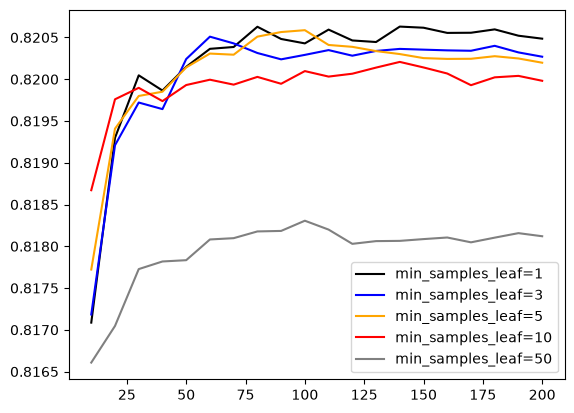

In [361]:
colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    
    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()

In [362]:
min_samples_leaf = 1

In [363]:
#train on best parameters
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=max_depth,
                            min_samples_leaf=min_samples_leaf,
                            random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [364]:
y_pred = rf.predict_proba(X_val)[:,1]
auc_trf = roc_auc_score(y_val, y_pred)
auc_trf

0.8204854853422776

In [365]:
#save this score
model_score['Tuned_Random_forest'] = round(auc_trf, 4)
model_score

{'Classifiction': 0.8256,
 'Decision_Tree': 0.6549,
 'Tuned_Decision_Tree': 0.8101,
 'Random_forest': 0.7667,
 'Tuned_Random_forest': 0.8205}

## Train on XG Boost

In [366]:
train_dicts = df_train.to_dict(orient='records')

In [367]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [368]:
X_train.shape

(42414, 44)

In [369]:
# For xgboost, we need to transform train data in a dtrain matrix before fitting model
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [370]:
xgb_params = {
'eta': 0.3, 
'max_depth': 6,
'min_child_weight': 1,

'objective': 'binary:logistic',
'eval_metric': 'auc',
'nthread': 8,

'seed': 1,
'verbosity': 1,
}

# train model on above transformed datasets
model = xgb.train(xgb_params, dtrain, num_boost_round=10)

In [371]:
y_pred = model.predict(dval)
auc_xgb = roc_auc_score(y_val, y_pred)
auc_xgb

0.8239163253958139

In [372]:
#save this score
model_score['XG_Boost'] = round(auc_xgb, 4)
model_score

{'Classifiction': 0.8256,
 'Decision_Tree': 0.6549,
 'Tuned_Decision_Tree': 0.8101,
 'Random_forest': 0.7667,
 'Tuned_Random_forest': 0.8205,
 'XG_Boost': 0.8239}

### Lets tune XG Boost

In [373]:
scores = {}

### Check with eta=0.01

In [374]:
watchlist = [(dtrain, 'train'), (dval,'val')]

In [375]:
%%capture output

xgb_params = {
    'eta': 0.01, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [376]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [377]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.01'

### check with eta=0.1

In [378]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [379]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.1'

### check with eta=0.3

In [380]:
%%capture output

xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)


In [381]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.3'

### check with eta=1.0

In [382]:
%%capture output

xgb_params = {
    'eta': 1.0, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)


In [383]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=1.0'

### Plot all the results

In [384]:
scores

{'eta=0.01':     num_iter  train_auc  val_auc
 0          0    0.80762  0.80490
 1          5    0.80985  0.80834
 2         10    0.81083  0.80933
 3         15    0.81175  0.81000
 4         20    0.81226  0.81025
 5         25    0.81287  0.81056
 6         30    0.81383  0.81109
 7         35    0.81421  0.81120
 8         40    0.81485  0.81176
 9         45    0.81536  0.81233
 10        50    0.81589  0.81268
 11        55    0.81636  0.81309
 12        60    0.81673  0.81331
 13        65    0.81718  0.81370
 14        70    0.81755  0.81400
 15        75    0.81802  0.81441
 16        80    0.81829  0.81459
 17        85    0.81876  0.81484
 18        90    0.81916  0.81513
 19        95    0.81956  0.81539
 20       100    0.81987  0.81557
 21       105    0.82020  0.81582
 22       110    0.82048  0.81601
 23       115    0.82081  0.81620
 24       120    0.82115  0.81645
 25       125    0.82152  0.81675
 26       130    0.82183  0.81700
 27       135    0.82216  0.81720
 2

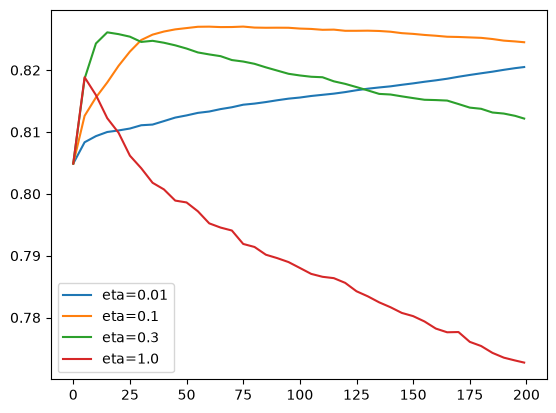

In [385]:
for eta, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=eta)

plt.legend()

### Above plot shows eta=0.1 has best results and we can freeze it

## Now lets move to find out max_depth

In [386]:
scores = {}

### check max_depth = 3

In [387]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 3, 
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [388]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=3'

### check max_depth = 4

In [389]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [390]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=4'

### check max_depth = 10

In [391]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 10, 
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [392]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=10'

### check max_depth = 6

In [393]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 6, 
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [394]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=6'

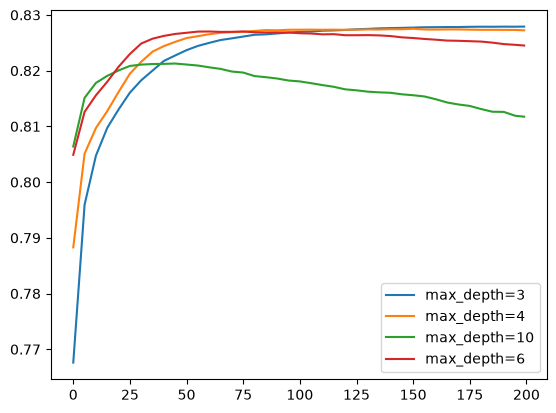

In [395]:
for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)

plt.legend()

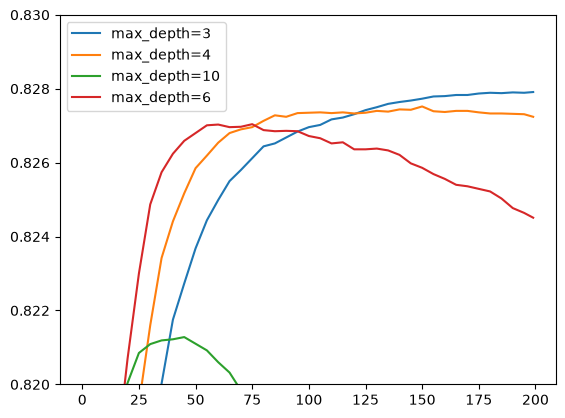

In [396]:
# lets zoom in to check closely

for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)

plt.ylim(0.82, 0.83)
plt.legend()

In [397]:
### Max depth=4 has best result. Lets freeze it

### So eta=0.1, max_depth=4. now lets check for mini_child_weight=1, 10 & 30

In [398]:
scores = {}

### check for mini_child=1

In [399]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [400]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=1'

In [401]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 10,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [402]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=10'

In [403]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 30,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [404]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=30'

In [405]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 40,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [406]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=40'

In [407]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 60,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [408]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=60'

In [409]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 100,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [410]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=100'

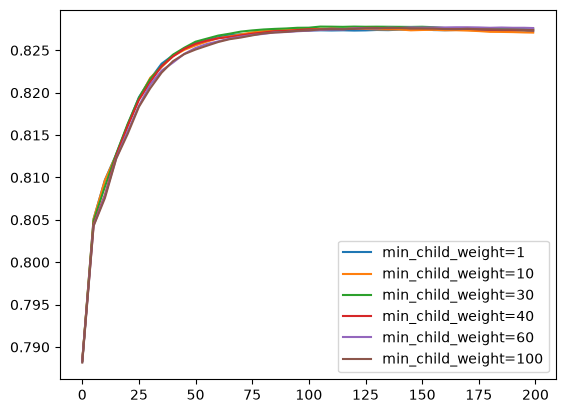

In [411]:
for min_child_weight, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=min_child_weight)


plt.legend()

In [412]:
## zoom in between 0.82 and 0.83

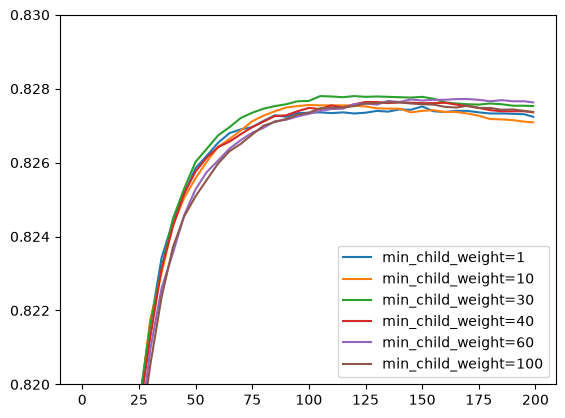

In [413]:
for min_child_weight, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=min_child_weight)

plt.ylim(0.82, 0.83)
plt.legend()

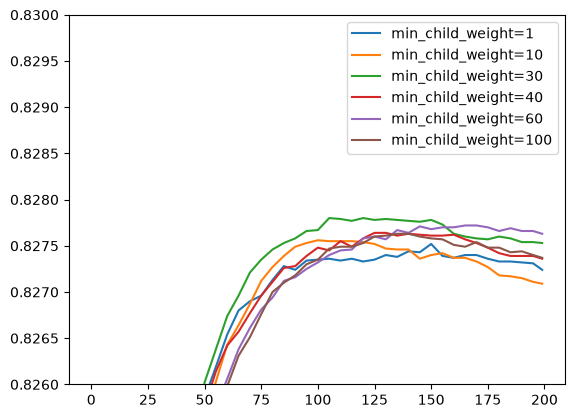

In [414]:
for min_child_weight, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=min_child_weight)

plt.ylim(0.826, 0.830)
plt.legend()

### In above comparision, min_child_weight=60 is best. 

### Train final model

In [469]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 60,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

tuned_xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [470]:
y_pred = tuned_xgb_model.predict(dval)
tuned_xgb_auc = roc_auc_score(y_val, y_pred)
tuned_xgb_auc

0.8276347353734417

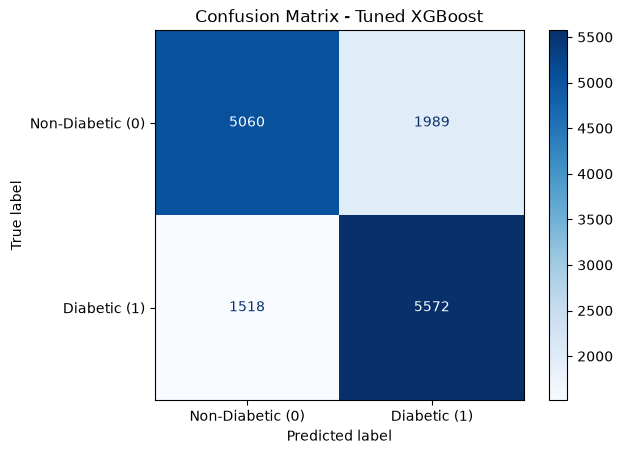

In [478]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict validation data
y_pred_prob = tuned_xgb_model.predict(dval)

# Convert probabilities into binary predictions
y_pred = (y_pred_prob >= 0.5).astype(int)
# Generate confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Non-Diabetic (0)', 'Diabetic (1)']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Tuned XGBoost')
plt.show()


In [479]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_val, y_pred,
    target_names=['No Diabetes', 'Diabetes']
))

print("ROC-AUC:", roc_auc_score(y_val, y_pred_prob))

Confusion Matrix:
[[5060 1989]
 [1518 5572]]

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.77      0.72      0.74      7049
    Diabetes       0.74      0.79      0.76      7090

    accuracy                           0.75     14139
   macro avg       0.75      0.75      0.75     14139
weighted avg       0.75      0.75      0.75     14139

ROC-AUC: 0.8276347353734417


In [417]:
#save this score
model_score['Tuned_XG_Boost'] = round(tuned_xgb_auc, 4)
model_score

{'Classifiction': 0.8256,
 'Decision_Tree': 0.6549,
 'Tuned_Decision_Tree': 0.8101,
 'Random_forest': 0.7667,
 'Tuned_Random_forest': 0.8205,
 'XG_Boost': 0.8239,
 'Tuned_XG_Boost': 0.8276}

In [418]:
model_df = pd.DataFrame.from_dict(model_score, orient='index', columns=['AUC']).reset_index()

In [419]:
model_df.columns = ['Model', 'AUC']

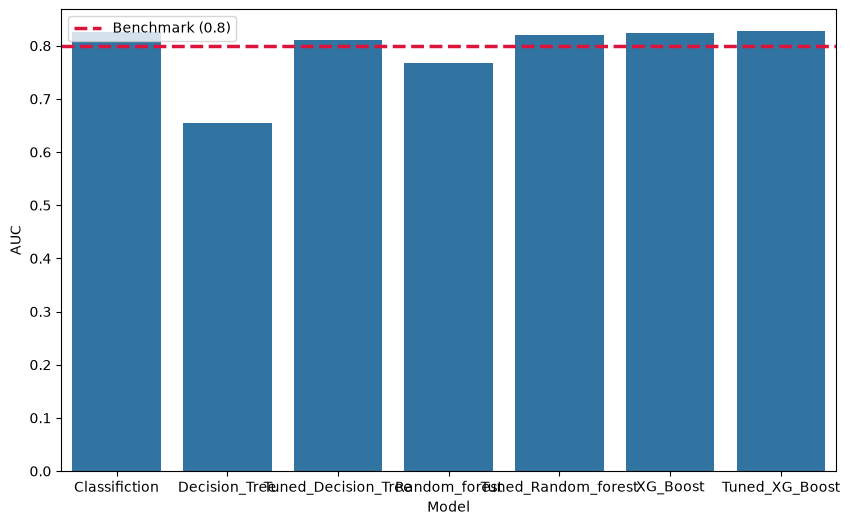

In [420]:
plt.figure(figsize=(10, 6))

benchmark_value = 0.8
plt.axhline(
    y=benchmark_value,
    color="crimson",
    linestyle="--",
    linewidth=2.5,
    label=f"Benchmark ({benchmark_value})",
)

sns.barplot(data=model_df, x='Model', y='AUC')
plt.legend()
plt.show()

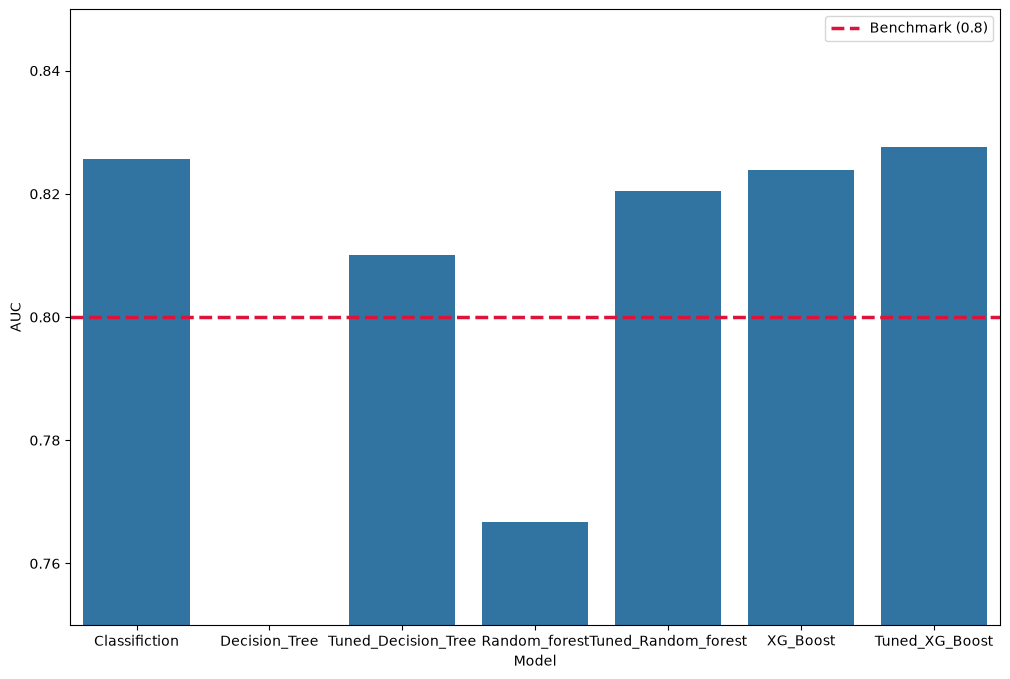

In [421]:
plt.figure(figsize=(12, 8))

benchmark_value = 0.8
plt.axhline(
    y=benchmark_value,
    color="crimson",
    linestyle="--",
    linewidth=2.5,
    label=f"Benchmark ({benchmark_value})",
)

plt.ylim(0.75, 0.85)

sns.barplot(data=model_df, x='Model', y='AUC')
plt.legend()
plt.show()

### It is clear from above chart that tuned XG boost has max auc as '0.828'

## Now lets check final model using Full train for trained XGboost

In [422]:
df_full_train

,genhlth,highbp,age,highchol,diffwalk,income,heartdiseaseorattack,education,physactivity,physhlth,bmi
0,fair,high_bp,80,no_high_col,yes,"15,000_to_20,000",yes,high_school_graduate_/_ged,no,15.0,36.0
1,fair,high_bp,64,no_high_col,yes,"10,000_to_15,000",no,high_school_graduate_/_ged,no,7.0,22.0
2,very_good,no_high_bp,49,no_high_col,no,"75,000_or_more",no,college_graduate_(4+_years),yes,0.0,21.0
3,good,high_bp,69,high_col,no,"75,000_or_more",no,college_graduate_(4+_years),yes,0.0,33.0
4,good,high_bp,74,high_col,no,"25,000_to_35,000",no,college_graduate_(4+_years),yes,8.0,34.0
...,...,...,...,...,...,...,...,...,...,...,...
56548,good,no_high_bp,64,high_col,no,"75,000_or_more",no,high_school_graduate_/_ged,yes,0.0,28.0
56549,fair,no_high_bp,69,high_col,yes,"35,000_to_50,000",no,some_college_/_technical_school,no,30.0,24.0
56550,very_good,no_high_bp,49,no_high_col,no,"50,000_to_75,000",no,some_college_/_technical_school,yes,0.0,22.0
56551,excellent,high_bp,79,no_high_col,no,"35,000_to_50,000",yes,college_graduate_(4+_years),yes,0.0,27.0


In [423]:
y_full_train

array([1, 1, 0, ..., 0, 1, 0], shape=(56553,))

In [424]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [425]:
dfulltrain = xgb.DMatrix(
    X_full_train,
    label=y_full_train,
    feature_names=dv.get_feature_names_out().tolist()
)

In [426]:
dtest = xgb.DMatrix(X_test, feature_names=dv.get_feature_names_out().tolist())

In [482]:
y_pred = tuned_xgb_model.predict(dtest)
df_full_auc = roc_auc_score(y_test, y_pred)
df_full_auc

0.8205785291880827

In [483]:
# Predict test probabilities
y_test_pred_prob = tuned_xgb_model.predict(dtest)

# Convert probabilities into binary predictions
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Evaluate final test performance
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Test ROC-AUC:", roc_auc_score(y_test, y_test_pred_prob))
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['No Diabetes', 'Diabetes']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Test ROC-AUC: 0.8205785291880827
Test Accuracy: 0.743475493316359

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.77      0.71      0.73      7107
    Diabetes       0.72      0.78      0.75      7032

    accuracy                           0.74     14139
   macro avg       0.75      0.74      0.74     14139
weighted avg       0.75      0.74      0.74     14139


Confusion Matrix:
[[5013 2094]
 [1533 5499]]


## Save the model

In [509]:
import os
import pickle

In [513]:
eta = 0.1
max_depth = 4
min_child_weight = 60

# Create models directory if it does not exist
os.makedirs('../models', exist_ok=True)

output_file = f"../models/xgb_tuned_eta_{str(eta).replace('.', '_')}_depth_{max_depth}_min_child_{min_child_weight}.bin"
output_file

'../models/xgb_tuned_eta_0_1_depth_4_min_child_60.bin'

In [514]:
f_out = open(output_file, 'wb') 
pickle.dump((dv, tuned_xgb_model), f_out)
f_out.close()

In [512]:
dv, tuned_xgb_model

(DictVectorizer(sparse=False), <xgboost.core.Booster at 0x1bdc53f7550>)

In [515]:
# Load saved model
model_file = '../models/xgb_tuned_eta_0_1_depth_4_min_child_60.bin'

with open(model_file, 'rb') as f_in:
    dv_loaded, model_loaded = pickle.load(f_in)

print(dv_loaded)
print(model_loaded)

DictVectorizer(sparse=False)


In [516]:
patient = df_full_train.iloc[0].to_dict()
patient

{'genhlth': 'fair',
 'highbp': 'high_bp',
 'age': '80',
 'highchol': 'no_high_col',
 'diffwalk': 'yes',
 'income': '15,000_to_20,000',
 'heartdiseaseorattack': 'yes',
 'education': 'high_school_graduate_/_ged',
 'physactivity': 'no',
 'physhlth': 15.0,
 'bmi': 36.0}

In [505]:
X = dv.transform([patient])
X

array([[ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,
        36.,  0.,  1.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,
         0.,  0.,  1.,  1.,  0.,  0.,  1.,  0.,  1.,  0.,  0.,  0.,  0.,
         0.,  0.,  1.,  0., 15.]])

In [506]:
Xtest = xgb.DMatrix(X, feature_names=dv.get_feature_names_out().tolist())

In [517]:
model_loaded.predict(Xtest)

array([0.8388256], dtype=float32)

In [502]:
%pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.
